# NeuroScan — Phase 2, Track 3: second backbone, Grad-CAM and error analysis

**Owner:** Mania Ali (23L-0876) · **Course:** DataScience, FAST-NUCES Lahore

## What this notebook does

Tracks 1 and 2 trained a CNN from scratch (accuracy 0.806) and EfficientNetB0 (tuned: 0.8826 with seed 42, 0.8685 ± 0.0199 over two seeds).
Track 3 answers three questions:

1. **Is EfficientNet the right backbone?** We train a second ImageNet backbone (**ResNet50**, one of the two allowed by `PHASE2.md`) with the same
   pipeline, seed, augmentation and metrics, and the same BatchNorm fix as Track 2.
2. **Does the model look at the tumour or at the image format?** Phase 1 found that image resolution almost gives the class away
   (Cramér's V = 0.52: about 96% of tumour images are 512×512, against 1% of "no tumour" images). Images were centre-padded with black to a square,
   so a non-square original leaves black bands that a CNN could use. We test this three ways:
   * **Grad-CAM**: where the model looks, measured over the whole test set and not only shown on a few pictures;
   * **Accuracy by original format**: do tumour images that are *not* 512×512 get called "no tumour" more often?
   * **A counterfactual test**: take tumour scans that are 512×512, change only their size or padding, and see whether the prediction changes.
3. **Why does the model fail?** Error analysis of the confusions Track 2 reported (meningioma → pituitary, tumour → "no tumour"), using Grad-CAM,
   image metadata and agreement between the two backbones.

| Section | What |
|---|---|
| 0 | Setup, configuration, saving progress to Google Drive |
| 1–2 | Data (shared pipeline) and the ResNet50 model |
| 3–4 | Tuning: head learning rate, then fine-tuning depth × learning rate |
| 5–6 | Choose the configuration on validation; retrain with 2 seeds; test once |
| 7 | Comparison with Tracks 1 and 2 |
| 8 | Load all models and their test predictions |
| 9 | Grad-CAM, with attention measured in the padding and background |
| 10 | Shortcut test 1: accuracy by original image format |
| 11 | Shortcut test 2: counterfactual resizing and padding |
| 12 | Error analysis |
| 13–14 | Save the artefacts; analysis and conclusions |

### Rules this notebook follows (from `PHASE2.md`)
* Data comes only from `neuroscan/data.py`, scoring only from `neuroscan/evaluate.py`. The split is Phase 1's and is never re-rolled.
* `preprocess="resnet50"` (caffe-style preprocessing that ResNet50 was trained with), `channels=3`.
* All choices use the **validation** split. The test split is used only for the final report and the analysis that follows it.
* The leaky pipeline is not used anywhere in this notebook.

## 0. Setup

Run this on **Google Colab with a GPU** (Runtime → Change runtime type → T4 GPU). The full run takes about **1–1.5 hours** on a T4.
Progress is saved to Google Drive, so after a disconnect you can simply *Run all* again and finished work is skipped.

In [1]:
# Colab: clone the repo. Local: this cell is a no-op (start Jupyter from the repo root).
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO   = "NeuroScan"
BRANCH = "main"            # change if your Track 3 branch already exists on GitHub

if IN_COLAB and not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "--branch", BRANCH,
                    "https://github.com/laibaamjad50/NeuroScan.git"], check=True)
if IN_COLAB:
    os.chdir(REPO)

print("working directory:", os.getcwd())
assert os.path.isdir("neuroscan"), "run this from the repository root"

working directory: /content/NeuroScan


In [2]:
!pip install -q -r requirements-phase2.txt

In [3]:
# processed_data/ is gitignored (about 300 MB). Rebuild it from the manifest; files already on disk are skipped.
!python scripts/build_processed_data.py

manifest rows     : 6,762
already on disk   : 0
to build          : 6,762
Preprocessing: 100% 6762/6762 [01:06<00:00, 102.04it/s]

built 6,762 | skipped 0 | failed 0
processed_data/ now holds 6,762 of 6,762 expected images


### Configuration

All the settings are here. `QUICK = True` runs the whole notebook with one epoch per run as a smoke test (a few minutes; the numbers are
meaningless). Set it to `False` for the real run.

In [4]:
import gc, json, os, sys, time, glob, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image as PILImage

sys.path.insert(0, os.getcwd())
from neuroscan import data, evaluate

# ---------------------------------------------------------------- configuration
QUICK    = False            # True = smoke test, results meaningless
SEED     = 42               # project-wide seed (PHASE2.md)
BACKBONE = "resnet50"       # "resnet50" or "mobilenetv2", the two allowed for Track 3
WEIGHTS  = "imagenet"
MODEL_NAME = f"{BACKBONE}_tuned"     # -> models/resnet50_tuned.keras, results/resnet50_tuned_metrics.json

BATCH    = 32
PATIENCE = 4                                   # early stopping on val_loss
EP_HEAD       = 1 if QUICK else 12             # tuning: max head epochs
EP_FT_TUNE    = 1 if QUICK else 6              # tuning: max fine-tuning epochs
EP_HEAD_FINAL = 1 if QUICK else 8              # final retrain (same budget as Track 2)
EP_FT_FINAL   = 1 if QUICK else 8

# Experiment 1: head learning rate (Track 2 found dropout 0.3 vs 0.5 a tie, so dropout is fixed at 0.3)
HEAD_GRID = [dict(lr_head=lr, dropout=0.3) for lr in (1e-3, 3e-4)]
# Experiment 2: how much of the base to unfreeze x fine-tuning learning rate.
# ResNet50: the last 32 layers are the whole conv5 stage; 72 = conv5 + the last four conv4 blocks.
FT_LAYERS = {"resnet50": (32, 72), "mobilenetv2": (30, 60)}[BACKBONE]
FT_GRID   = [dict(ft_layers=n, lr_ft=lr) for n in FT_LAYERS for lr in (1e-5, 3e-5)]
FINAL_SEEDS = [42] if QUICK else [42, 7]       # same seeds as Track 2
if QUICK:
    HEAD_GRID, FT_GRID = HEAD_GRID[:1], FT_GRID[:1]

# Other teams' models analysed alongside ours (skipped with a message if the file is missing)
OTHER_MODELS = {
    "effnet_tuned": ("models/effnet_tuned.keras", "efficientnet"),   # Track 2, the main model
    "effnet_clean": ("models/effnet_clean.keras", "efficientnet"),   # Track 1
}

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "NONE - this will be very slow")

report = data.verify(full=True)
print("\nPhase 1 outputs:", "OK" if report["ok"] else "PROBLEM", "|", report["counts"])
for p in report["problems"]:
    print("  -", p)
assert report["ok"], "fix the Phase 1 outputs before training"
CLASSES = report["classes"]
STATS = data.load_stats()
NOTUMOR = CLASSES.index("notumor")
print("classes:", CLASSES)

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Phase 1 outputs: OK | {'train': 4156, 'val': 1039, 'test': 1567}
classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


### Saving progress and resuming (Google Drive)

Same system as Track 2. Each finished run, each head model's weights, and each final seed are saved to `My Drive/NeuroScan_Phase2_Track3/`
straight away; an interrupted run continues from its last finished epoch. On *Run all* after a disconnect, finished work prints `[skip]`.
Set `RESET = True` to start from scratch (do this if you change the grids or epochs).

In [5]:
import shutil

RESET = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/NeuroScan_Phase2_Track3"
else:
    DRIVE_DIR = os.path.abspath("track3_cache")       # local runs: keep this folder out of git
DRIVE_DIR += "_QUICK" if QUICK else ""
CACHE, BACKUP = os.path.join(DRIVE_DIR, "cache"), os.path.join(DRIVE_DIR, "backup")

if RESET and os.path.isdir(DRIVE_DIR):
    shutil.rmtree(DRIVE_DIR); print("saved progress deleted")
os.makedirs(CACHE, exist_ok=True); os.makedirs(BACKUP, exist_ok=True)

def save_json(name, obj):
    path, tmp = os.path.join(CACHE, name + ".json"), os.path.join(CACHE, name + ".json.tmp")
    with open(tmp, "w") as fh:
        json.dump(obj, fh, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
    os.replace(tmp, path)

def load_json(name, default=None):
    p = os.path.join(CACHE, name + ".json")
    return json.load(open(p)) if os.path.exists(p) else default

def wpath(tag):
    return os.path.join(CACHE, tag + ".weights.h5")

def save_weights(model, tag):
    tmp = os.path.join(CACHE, tag + "_tmp.weights.h5")     # write, then rename: never a half-written file
    model.save_weights(tmp); os.replace(tmp, wpath(tag))

MINE = ("track3_", MODEL_NAME + "_")       # only our own files are synced; other tracks' files are never touched
def sync_to_drive():
    os.makedirs(f"{DRIVE_DIR}/results", exist_ok=True)
    for f in os.listdir("results"):
        if f.startswith(MINE):
            shutil.copy(f"results/{f}", f"{DRIVE_DIR}/results/{f}")
    if os.path.exists(f"models/{MODEL_NAME}.keras"):
        shutil.copy(f"models/{MODEL_NAME}.keras", f"{DRIVE_DIR}/{MODEL_NAME}.keras")

def restore_from_drive():
    n = 0
    if os.path.isdir(f"{DRIVE_DIR}/results"):
        for f in os.listdir(f"{DRIVE_DIR}/results"):
            if f.startswith(MINE):
                shutil.copy(f"{DRIVE_DIR}/results/{f}", f"results/{f}"); n += 1
    if os.path.exists(f"{DRIVE_DIR}/{MODEL_NAME}.keras"):
        shutil.copy(f"{DRIVE_DIR}/{MODEL_NAME}.keras", f"models/{MODEL_NAME}.keras"); n += 1
    return n

print("progress folder:", DRIVE_DIR)
print("restored", restore_from_drive(), "file(s) from a previous session")
print("finished runs found:", [r["name"] for r in load_json("all_runs", [])] or "none (fresh start)")

Mounted at /content/drive
progress folder: /content/drive/MyDrive/NeuroScan_Phase2_Track3
restored 26 file(s) from a previous session
finished runs found: ['head_lr0.001_do0.3', 'head_lr0.0003_do0.3', 'ft_head_lr0.001_do0.3_top32_lr1e-05', 'ft_head_lr0.001_do0.3_top32_lr3e-05', 'ft_head_lr0.001_do0.3_top72_lr1e-05', 'ft_head_lr0.001_do0.3_top72_lr3e-05']


## 1. Data

The shared clean pipeline with ResNet50 settings: 3 channels (the greyscale PNG repeated across RGB), `preprocess="resnet50"` (RGB→BGR and
ImageNet mean subtraction, as ResNet50 was trained), augmentation on the training split only. `cache=True` keeps the decoded images in RAM
(about 210 MB for train), which makes every epoch after the first much faster without changing the data.

In [6]:
PREPROCESS = BACKBONE            # data.py has a preprocess mode with the same name as each allowed backbone

def make_ds(seed=SEED, augment=True, preprocess=PREPROCESS):
    return data.make_datasets(data.DataConfig(preprocess=preprocess, channels=3, batch_size=BATCH,
                                              seed=seed, augment=augment, cache=True))

ds = make_ds()
info = ds["info"]
CLASS_WEIGHTS = info["class_weights"]

print("split sizes  :", info["counts"])
print("input shape  :", info["input_shape"])
print("class weights:", {CLASSES[k]: round(v, 3) for k, v in CLASS_WEIGHTS.items()})

x, y = next(iter(ds["train"]))
print(f"batch value range: {float(tf.reduce_min(x)):.1f} to {float(tf.reduce_max(x)):.1f}"
      "  (ResNet50 preprocessing: about -124 to +152, i.e. 0-255 minus the ImageNet mean)")

split sizes  : {'train': 4156, 'val': 1039, 'test': 1567}
input shape  : (224, 224, 3)
class weights: {'glioma': 0.93, 'meningioma': 1.009, 'notumor': 1.126, 'pituitary': 0.957}
batch value range: -123.7 to 151.1  (ResNet50 preprocessing: about -124 to +152, i.e. 0-255 minus the ImageNet mean)


## 2. Model, with Track 2's BatchNorm fix

**Architecture** (identical head to Track 2, so only the backbone differs): ResNet50 (ImageNet weights, no top) → global average pooling →
dropout → Dense(256, ReLU) → dropout → Dense(4, softmax).

**Fine-tuning safely** (the three fixes from Track 2):
1. The base is called with `training=False`, so BatchNorm runs in inference mode.
2. After unfreezing, every BatchNorm layer is set back to `trainable=False`.
3. The head's weights are kept, and fine-tuning is rolled back if it does not improve validation macro-F1.

In [7]:
BACKBONES = {"resnet50": keras.applications.ResNet50, "mobilenetv2": keras.applications.MobileNetV2}

def build_model(dropout=0.3, units=256, n_classes=4):
    """Backbone (frozen) + Track 2's classification head. Returns (model, base)."""
    base = BACKBONES[BACKBONE](include_top=False, weights=WEIGHTS, input_shape=info["input_shape"])
    base.trainable = False
    inputs = keras.Input(shape=info["input_shape"])
    h = base(inputs, training=False)                 # BatchNorm always in inference mode
    h = layers.GlobalAveragePooling2D()(h)
    h = layers.Dropout(dropout)(h)
    h = layers.Dense(units, activation="relu")(h)
    h = layers.Dropout(dropout)(h)
    out = layers.Dense(n_classes, activation="softmax")(h)
    return keras.Model(inputs, out, name=f"{BACKBONE}_track3"), base


def set_trainable(base, n_layers):
    """Unfreeze the last `n_layers` of the base, keeping every BatchNorm frozen."""
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


def fit_phase(model, train_ds, val_ds, lr, epochs, tag):
    """One training phase (always re-compiles, which is required after changing `trainable`).
    BackupAndRestore saves every epoch to Drive, so an interrupted phase resumes where it stopped."""
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    cbs = [keras.callbacks.BackupAndRestore(os.path.join(BACKUP, tag), save_freq="epoch"),
           keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                         restore_best_weights=True, verbose=1),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                             min_lr=1e-7, verbose=1)]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     class_weight=CLASS_WEIGHTS, callbacks=cbs, verbose=2)


def score(model, ds_split, split):
    """Score with the shared metric code. `split` must be 'val' or 'test' (unshuffled)."""
    probs = model.predict(ds_split, verbose=0)
    return evaluate.compute_metrics(data.y_true(split), probs.argmax(1), CLASSES, y_prob=probs)


m, b = build_model()
print(f"parameters: {m.count_params():,} | base layers: {len(b.layers)} | "
      f"BatchNorm layers in base: {sum(isinstance(l, layers.BatchNormalization) for l in b.layers)}")
for n in FT_LAYERS:
    print(f"  unfreezing the last {n:>3} layers starts at '{b.layers[-n].name}'")
set_trainable(b, FT_LAYERS[-1])
n_bn = sum(l.trainable for l in b.layers if isinstance(l, layers.BatchNormalization))
print(f"after set_trainable({FT_LAYERS[-1]}): {sum(l.trainable for l in b.layers)} base layers trainable, "
      f"BatchNorm trainable = {n_bn} (must be 0)")
assert n_bn == 0
del m, b; _ = gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
parameters: 24,113,284 | base layers: 175 | BatchNorm layers in base: 53
  unfreezing the last  32 layers starts at 'conv5_block1_1_conv'
  unfreezing the last  72 layers starts at 'conv4_block3_1_conv'
after set_trainable(72): 50 base layers trainable, BatchNorm trainable = 0 (must be 0)


## 3. Experiment 1 — head training (backbone frozen)

Only the new head is trained. The grid varies the head learning rate (1e-3 vs 3e-4); dropout is fixed at 0.3 because Track 2 found 0.3 and
0.5 tied. **Selection metric: validation macro-F1.**

In [8]:
all_runs = load_json("all_runs", [])

def finished():
    return {r["name"] for r in all_runs}

def run_row(name, stage, hp, ft_layers, lr_ft, epochs, v, extra=None):
    row = dict(name=name, stage=stage, lr_head=hp["lr_head"], dropout=hp["dropout"],
               ft_layers=ft_layers, lr_ft=lr_ft, epochs=epochs,
               val_acc=v["accuracy"], val_macro_f1=v["macro_f1"],
               val_tumour_missed=v.get("tumour_missed_rate"))
    row.update(extra or {})
    return row

for hp in HEAD_GRID:
    name = f"head_lr{hp['lr_head']:g}_do{hp['dropout']:g}"
    if name in finished():
        print(f"[skip] {name} - already finished"); continue
    print(f"\n########## {name}")
    t0 = time.time()
    keras.utils.set_random_seed(SEED)
    model, base = build_model(hp["dropout"])
    h = fit_phase(model, ds["train"], ds["val"], hp["lr_head"], EP_HEAD, tag=name)
    v = score(model, ds["val"], "val")
    save_weights(model, f"head_{name}")                            # weights first ...
    all_runs.append(run_row(name, "head", hp, 0, None, len(h.history["loss"]), v,
                            dict(minutes=(time.time() - t0) / 60)))
    save_json("all_runs", all_runs)                                 # ... then the row
    print(f"-> val acc {v['accuracy']:.4f} | val macro-F1 {v['macro_f1']:.4f} | {(time.time()-t0)/60:.1f} min")
    del model, base; gc.collect()

exp1 = pd.DataFrame([r for r in all_runs if r["stage"] == "head"])
best_head = exp1.sort_values(["val_macro_f1", "val_acc"], ascending=False).iloc[0]
BEST_HEAD = dict(name=best_head["name"], lr_head=float(best_head["lr_head"]), dropout=float(best_head["dropout"]))
head_val = float(best_head["val_macro_f1"])
print("best head:", BEST_HEAD, f"(val macro-F1 {head_val:.4f})")
exp1[["name", "epochs", "val_acc", "val_macro_f1", "val_tumour_missed"]].round(4)

[skip] head_lr0.001_do0.3 - already finished
[skip] head_lr0.0003_do0.3 - already finished
best head: {'name': 'head_lr0.001_do0.3', 'lr_head': 0.001, 'dropout': 0.3} (val macro-F1 0.9213)


,name,epochs,val_acc,val_macro_f1,val_tumour_missed
0,head_lr0.001_do0.3,12,0.9211,0.9213,0.0111
1,head_lr0.0003_do0.3,12,0.9182,0.9184,0.0173


## 4. Experiment 2 — fine-tuning

From the best head, unfreeze the top *N* layers of ResNet50 (BatchNorm stays frozen) and train at a small learning rate.
* `ft_layers`: 32 (the conv5 stage only) or 72 (conv5 + the last four conv4 blocks)
* `lr_ft`: 1e-5 or 3e-5 (Track 2 found 3e-5 better for EfficientNet at every depth)

`delta_vs_head` is the change in validation macro-F1 caused by fine-tuning; negative means it hurt.

In [9]:
for ft in FT_GRID:
    name = f"ft_{BEST_HEAD['name']}_top{ft['ft_layers']}_lr{ft['lr_ft']:g}"
    if name in finished():
        print(f"[skip] {name} - already finished"); continue
    print(f"\n########## {name}")
    t0 = time.time()
    keras.utils.set_random_seed(SEED)
    model, base = build_model(BEST_HEAD["dropout"])
    model.load_weights(wpath(f"head_{BEST_HEAD['name']}"))
    set_trainable(base, ft["ft_layers"])
    h = fit_phase(model, ds["train"], ds["val"], ft["lr_ft"], EP_FT_TUNE, tag=name)
    v = score(model, ds["val"], "val")
    all_runs.append(run_row(name, "finetune", BEST_HEAD, ft["ft_layers"], ft["lr_ft"],
                            len(h.history["loss"]), v,
                            dict(delta_vs_head=v["macro_f1"] - head_val, minutes=(time.time() - t0) / 60)))
    save_json("all_runs", all_runs)
    print(f"-> val macro-F1 {v['macro_f1']:.4f} (head only {head_val:.4f}, delta {v['macro_f1']-head_val:+.4f})")
    del model, base; gc.collect()

runs = pd.DataFrame(all_runs)
runs.to_csv("results/track3_tuning_runs.csv", index=False)
exp2 = runs[runs["stage"] == "finetune"]
exp2[["name", "ft_layers", "lr_ft", "epochs", "val_acc", "val_macro_f1", "delta_vs_head", "val_tumour_missed"]].round(4)

[skip] ft_head_lr0.001_do0.3_top32_lr1e-05 - already finished
[skip] ft_head_lr0.001_do0.3_top32_lr3e-05 - already finished
[skip] ft_head_lr0.001_do0.3_top72_lr1e-05 - already finished
[skip] ft_head_lr0.001_do0.3_top72_lr3e-05 - already finished


,name,ft_layers,lr_ft,epochs,val_acc,val_macro_f1,delta_vs_head,val_tumour_missed
2,ft_head_lr0.001_do0.3_top32_lr1e-05,32,0.0,6,0.9355,0.9361,0.0148,0.0136
3,ft_head_lr0.001_do0.3_top32_lr3e-05,32,0.0,6,0.9577,0.9581,0.0368,0.0050
4,ft_head_lr0.001_do0.3_top72_lr1e-05,72,0.0,6,0.9461,0.9462,0.0250,0.0062
5,ft_head_lr0.001_do0.3_top72_lr3e-05,72,0.0,6,0.9711,0.9715,0.0502,0.0012


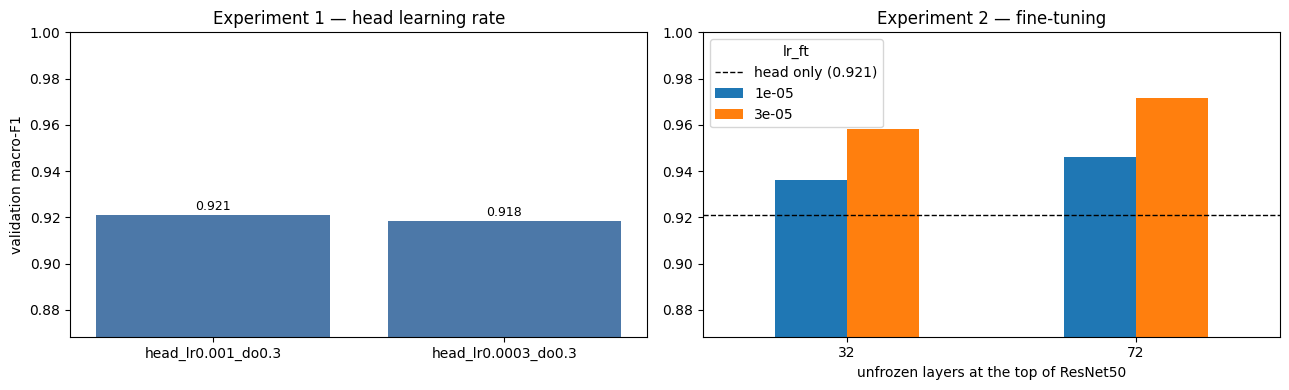

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(exp1["name"], exp1["val_macro_f1"], color="#4C78A8")
for i, v in enumerate(exp1["val_macro_f1"]):
    ax[0].text(i, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
ax[0].set_ylim(max(0, runs["val_macro_f1"].min() - 0.05), min(1, runs["val_macro_f1"].max() + 0.03))
ax[0].set_ylabel("validation macro-F1"); ax[0].set_title("Experiment 1 — head learning rate")
if len(exp2):
    pivot = exp2.pivot(index="ft_layers", columns="lr_ft", values="val_macro_f1")
    pivot.plot.bar(ax=ax[1], rot=0)
    ax[1].axhline(head_val, color="k", ls="--", lw=1, label=f"head only ({head_val:.3f})")
    ax[1].set_ylim(ax[0].get_ylim()); ax[1].legend(title="lr_ft")
ax[1].set_xlabel("unfrozen layers at the top of ResNet50"); ax[1].set_title("Experiment 2 — fine-tuning")
plt.tight_layout(); plt.savefig("results/track3_tuning.png", dpi=150, bbox_inches="tight"); plt.show()
sync_to_drive()

## 5. Choosing the final configuration (validation only)

The run with the highest validation macro-F1 wins. If it is a head-only run, the honest conclusion is that fine-tuning did not help ResNet50.

In [11]:
cand = runs[runs["stage"].isin(["head", "finetune"])].sort_values(["val_macro_f1", "val_acc"], ascending=False)
best = cand.iloc[0]
FINAL = dict(lr_head=float(best["lr_head"]), dropout=float(best["dropout"]),
             ft_layers=int(best["ft_layers"]), lr_ft=None if pd.isna(best["lr_ft"]) else float(best["lr_ft"]))
print("FINAL CONFIGURATION (chosen on validation macro-F1):", FINAL)
print(f"validation macro-F1 {best['val_macro_f1']:.4f}, runner-up {cand.iloc[1]['val_macro_f1']:.4f}"
      if len(cand) > 1 else "")

FINAL CONFIGURATION (chosen on validation macro-F1): {'lr_head': 0.001, 'dropout': 0.3, 'ft_layers': 72, 'lr_ft': 3e-05}
validation macro-F1 0.9715, runner-up 0.9581


## 6. Final model: retrain with two seeds, then test once

Seeds 42 and 7, as in Track 2, so the spreads are comparable. **Seed 42** is saved as `models/resnet50_tuned.keras` and its metrics go into the
shared comparison table; seed 7 only gives the spread. **This is the first place the test set is used.**

In [12]:
def train_final(cfg, seed):
    """Train one final seed, or reload it if a previous session finished it."""
    ds_s = make_ds(seed=seed)
    tag = f"final_s{seed}"
    keras.utils.set_random_seed(seed)
    model, base = build_model(cfg["dropout"])

    done = load_json(tag + "_final")
    if done and os.path.exists(wpath(tag + "_final")):
        print(f"[skip] seed {seed} - already trained, loading it")
        model.load_weights(wpath(tag + "_final"))
        return model, done["hists"], ds_s, done["kept"]

    head = load_json(tag + "_head")
    if head and os.path.exists(wpath(tag + "_head")):
        print(f"[skip] seed {seed} head phase - loading it")
        model.load_weights(wpath(tag + "_head")); hists = [head["hist"]]
    else:
        h = fit_phase(model, ds_s["train"], ds_s["val"], cfg["lr_head"], EP_HEAD_FINAL, tag=tag + "_head")
        hists = [{k: [float(x) for x in v] for k, v in h.history.items()}]
        save_weights(model, tag + "_head"); save_json(tag + "_head", dict(hist=hists[0]))
    f1_head = score(model, ds_s["val"], "val")["macro_f1"]

    kept_ft = False
    if cfg["ft_layers"] > 0:
        w_head = model.get_weights()
        set_trainable(base, cfg["ft_layers"])
        h_ft = fit_phase(model, ds_s["train"], ds_s["val"], cfg["lr_ft"], EP_FT_FINAL, tag=tag + "_ft")
        f1_ft = score(model, ds_s["val"], "val")["macro_f1"]
        if f1_ft >= f1_head:
            hists.append({k: [float(x) for x in v] for k, v in h_ft.history.items()}); kept_ft = True
        else:
            model.set_weights(w_head)
            print(f"!! fine-tune rolled back (val macro-F1 {f1_ft:.4f} < head {f1_head:.4f})")
    save_weights(model, tag + "_final"); save_json(tag + "_final", dict(hists=hists, kept=kept_ft))
    return model, hists, ds_s, kept_ft


def export_model(model, path):
    """Save without the optimizer state (it would roughly double the file size)."""
    clean = keras.models.clone_model(model)
    clean.set_weights(model.get_weights())
    clean.save(path)


seed_rows, final_model = [], None
for seed in FINAL_SEEDS:
    print(f"\n########## final run, seed {seed}")
    model, hists, ds_s, kept_ft = train_final(FINAL, seed)
    v = score(model, ds_s["val"], "val")
    if seed == SEED:
        t = evaluate.evaluate_model(model, ds_s["test"], CLASSES, name=MODEL_NAME, outdir="results")
        export_model(model, f"models/{MODEL_NAME}.keras")
        evaluate.plot_history(hists, f"results/{MODEL_NAME}_history.png", f"{BACKBONE} (tuned)")
        final_model, final_ds = model, ds_s
        sync_to_drive()
    else:
        t = score(model, ds_s["test"], "test")
        del model; gc.collect()
    seed_rows.append(dict(seed=seed, kept_finetune=kept_ft, val_acc=v["accuracy"], val_macro_f1=v["macro_f1"],
                          test_acc=t["accuracy"], test_macro_f1=t["macro_f1"],
                          test_tumour_missed=t.get("tumour_missed_rate")))
    print(f"seed {seed}: test accuracy {t['accuracy']:.4f} | test macro-F1 {t['macro_f1']:.4f}")

seeds = pd.DataFrame(seed_rows)
seeds.to_csv("results/track3_seeds.csv", index=False)
summary = seeds[["val_acc", "val_macro_f1", "test_acc", "test_macro_f1", "test_tumour_missed"]].agg(["mean", "std"]).T
summary.columns = ["mean", "std"]
print(f"\n{BACKBONE} (tuned), {len(seeds)} seed(s):")
print(summary.round(4).to_string())
seeds.round(4)


########## final run, seed 42
[skip] seed 42 - already trained, loading it
seed 42: test accuracy 0.9068 | test macro-F1 0.9062

########## final run, seed 7
[skip] seed 7 - already trained, loading it
seed 7: test accuracy 0.9190 | test macro-F1 0.9168

resnet50 (tuned), 2 seed(s):
                      mean     std
val_acc             0.9697  0.0020
val_macro_f1        0.9699  0.0017
test_acc            0.9129  0.0086
test_macro_f1       0.9115  0.0076
test_tumour_missed  0.0649  0.0330


,seed,kept_finetune,val_acc,val_macro_f1,test_acc,test_macro_f1,test_tumour_missed
0,42,True,0.9711,0.9711,0.9068,0.9062,0.0882
1,7,True,0.9682,0.9687,0.9190,0.9168,0.0416


resnet50_tuned
samples            1567
accuracy           0.9068
balanced accuracy  0.9065
macro F1           0.9062
macro precision    0.9185
macro recall       0.9065

class             prec     rec      f1      n
glioma          0.9755  0.8329  0.8986    383
meningioma      0.9578  0.8030  0.8736    396
notumor         0.7886  1.0000  0.8818    388
pituitary       0.9519  0.9900  0.9706    400

tumours called 'no tumour': 104 (8.82%)



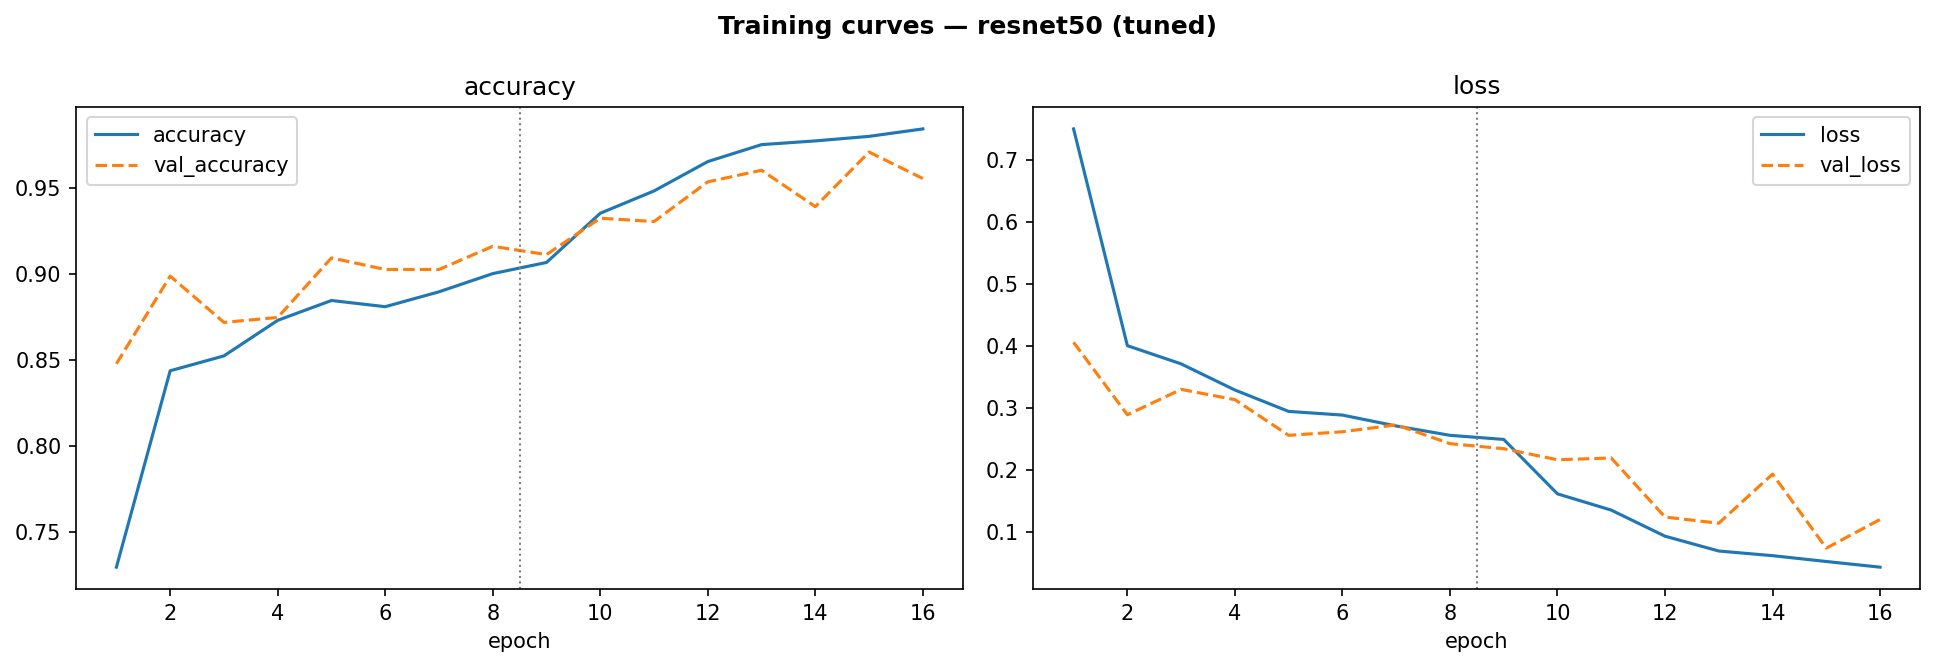

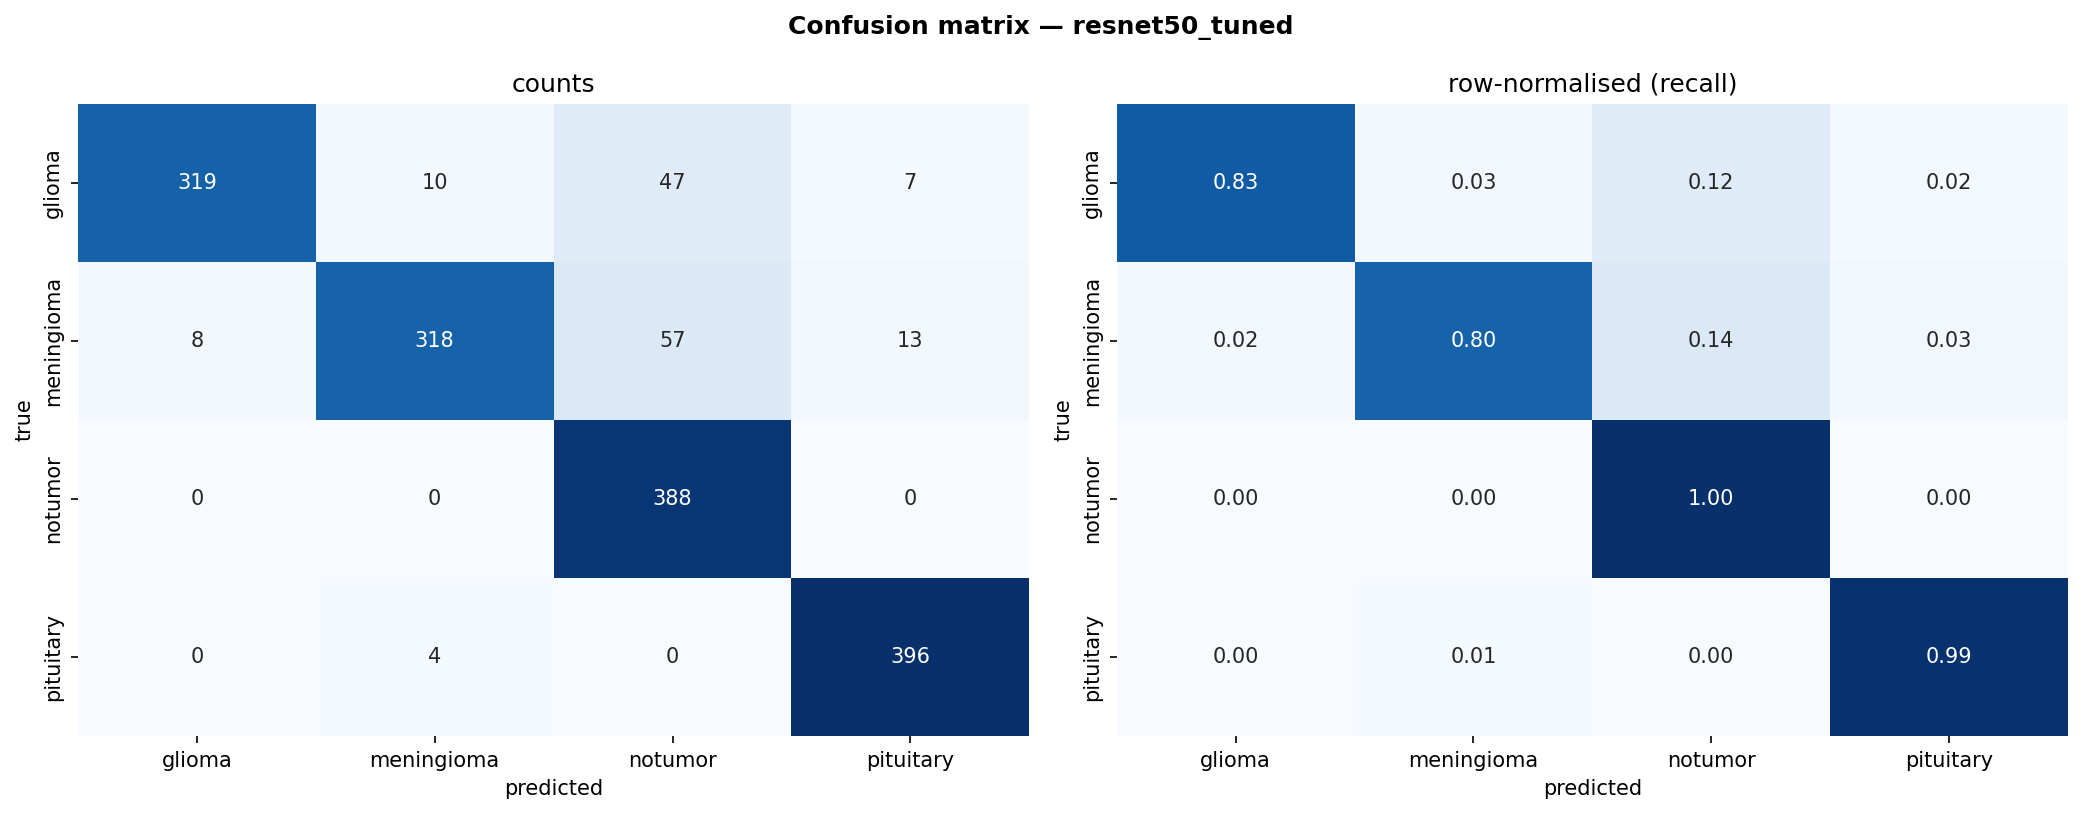

In [13]:
print(open(f"results/{MODEL_NAME}_report.txt").read())
from IPython.display import Image, display
display(Image(f"results/{MODEL_NAME}_history.png"))
display(Image(f"results/{MODEL_NAME}_confusion.png"))

## 7. Comparison with Tracks 1 and 2

Same split, preprocessing family, augmentation and metric code for every row. Leaky-pipeline rows are removed: they must never be quoted.
`save=False` leaves `results/comparison.*` alone (Track 1 owns it).

In [14]:
comp = evaluate.comparison_table("results", save=False)
comp = comp[~comp["model"].str.contains("leaky")].reset_index(drop=True)
comp.to_csv("results/track3_comparison.csv", index=False)
with open("results/track3_comparison.md", "w", encoding="utf-8") as fh:
    fh.write(evaluate._markdown(comp))

fig, ax = plt.subplots(1, 2, figsize=(12, 0.6 * len(comp) + 2))
c = comp.sort_values("macro_f1")
colors = ["#F58518" if m == MODEL_NAME else "#4C78A8" for m in c["model"]]
ax[0].barh(c["model"], c["macro_f1"], color=colors)
ax[0].set_xlim(c["macro_f1"].min() - 0.05, min(1, c["macro_f1"].max() + 0.03))
ax[0].set_xlabel("test macro-F1"); ax[0].set_title("Test macro-F1 (orange = Track 3)")
for i, v in enumerate(c["macro_f1"]): ax[0].text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
if "tumour_missed" in c:
    ax[1].barh(c["model"], c["tumour_missed"] * 100, color="#E45756")
    ax[1].set_xlabel("% of tumours predicted as 'no tumour'"); ax[1].set_title("Missed tumours (lower is better)")
    for i, v in enumerate(c["tumour_missed"] * 100): ax[1].text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout(); plt.savefig("results/track3_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()
comp

,model,n,accuracy,balanced_acc,macro_f1,macro_recall,macro_auc,tumour_missed
0,resnet50_tuned,1567,0.9068,0.9065,0.9062,0.9065,0.9797,0.0882
1,effnet_tuned,1567,0.8826,0.8823,0.8788,0.8823,0.9811,0.0585
2,effnet_clean_best,1567,0.8551,0.8544,0.8500,0.8544,0.9711,0.0560
3,baseline_cnn,1567,0.8060,0.8052,0.7976,0.8052,0.9336,0.1501


## 8. Load every model and its test predictions

From here on we analyse our ResNet50 **and** the EfficientNets from Tracks 1 and 2 on the same test images. Each model gets its own
preprocessing (EfficientNet expects 0–255, ResNet50 caffe-style).

For Grad-CAM we need the test images as arrays, so we load the 224×224 PNGs directly and apply the same steps as `data.py`
(greyscale → RGB → preprocessing). A check below confirms this gives the same predictions as the shared pipeline.

We also attach each test image's Phase 1 metadata (`cleaned_metadata.csv`): its **original width and height**, which we need for the shortcut tests.

In [15]:
manifest = data.load_manifest()
test_rows = manifest[manifest["final_split"] == "test"].reset_index(drop=True)
meta = pd.read_csv("data/cleaned_metadata.csv")
meta["processed_path"] = meta["processed_path"].str.replace("\\", "/", regex=False)
T = test_rows.merge(meta[["processed_path", "width", "height", "resolution", "mean", "std",
                          "edge_density", "n_outlier_flags"]], on="processed_path", how="left")
assert len(T) == len(test_rows) and T["width"].notna().all(), "metadata does not cover every test image"
y_true = np.array(data.y_true("test"))
assert (T["label_idx"].values == y_true).all(), "test order does not match data.y_true"

T["native_512"] = T["resolution"] == "512x512"
T["is_tumour"]  = T["label_idx"] != NOTUMOR
s = np.maximum(T["width"], T["height"])
T["pad_frac"] = 1 - (T["width"] * T["height"]) / (s * s)       # share of the 224x224 image that is black padding
T["padded"]   = T["pad_frac"] > 0.01

root = data.repo_root()
IMGS = np.stack([np.asarray(PILImage.open(os.path.join(root, p))) for p in T["processed_path"]])   # (N,224,224) uint8
print("test images:", IMGS.shape)
print("\nnative 512x512 by class (test set):")
print(pd.crosstab(T["label"], T["native_512"]))
print("\npadded (non-square original) by class:")
print(pd.crosstab(T["label"], T["padded"]))

test images: (1567, 224, 224)

native 512x512 by class (test set):
native_512  False  True 
label                   
glioma         65    318
meningioma    113    283
notumor       385      3
pituitary       8    392

padded (non-square original) by class:
padded      False  True 
label                   
glioma        331     52
meningioma    304     92
notumor       123    265
pituitary     400      0


In [16]:
PRE = {m: data._preprocess_fn(m, STATS) for m in ("efficientnet", "resnet50", "mobilenetv2")}

def to_input(imgs, mode):
    """uint8 (n,224,224) -> model input, exactly as data.py builds it."""
    x = tf.cast(tf.convert_to_tensor(imgs), tf.float32)[..., None]
    return PRE[mode](tf.image.grayscale_to_rgb(x))

def predict_arrays(model, imgs, mode, bs=64):
    return np.concatenate([model.predict(to_input(imgs[i:i + bs], mode), verbose=0)
                           for i in range(0, len(imgs), bs)])

MODELS = {MODEL_NAME: (final_model, PREPROCESS)}
for name, (path, mode) in OTHER_MODELS.items():
    if os.path.exists(path):
        MODELS[name] = (keras.models.load_model(path, compile=False), mode)
    else:
        print(f"[missing] {path} - {name} is left out of the analysis")

PROBS, PROBS_VAL = {}, {}
for name, (mdl, mode) in MODELS.items():
    ds_m = make_ds(preprocess=mode)
    PROBS[name] = mdl.predict(ds_m["test"], verbose=0)               # official: through the shared pipeline
    PROBS_VAL[name] = mdl.predict(ds_m["val"], verbose=0)
    check = predict_arrays(mdl, IMGS[:64], mode)
    diff = np.abs(check - PROBS[name][:64]).max()
    print(f"{name:<14} test acc {(PROBS[name].argmax(1) == y_true).mean():.4f} | "
          f"array path vs shared pipeline, max prob difference {diff:.2e}")
    assert diff < 1e-3, "the array path does not reproduce the shared pipeline"
    T[f"pred_{name}"] = PROBS[name].argmax(1)
    T[f"conf_{name}"] = PROBS[name].max(1)
    T[f"correct_{name}"] = T[f"pred_{name}"] == y_true

resnet50_tuned test acc 0.9068 | array path vs shared pipeline, max prob difference 0.00e+00
effnet_tuned   test acc 0.8826 | array path vs shared pipeline, max prob difference 0.00e+00
effnet_clean   test acc 0.8551 | array path vs shared pipeline, max prob difference 0.00e+00


**A free extra: ensemble of EfficientNet and ResNet50.** Averaging the two models' probabilities costs nothing to try, and Track 2 listed it as
a possible improvement. This was decided before looking at the test set (it has no settings to tune), and we report validation alongside test.
It is written to `results/track3_ensemble.json`, deliberately *not* a `*_metrics.json`, so it does not enter the shared table unless the team agrees.

In [17]:
if "effnet_tuned" in PROBS:
    y_val = np.array(data.y_true("val"))
    ens_val  = (PROBS_VAL["effnet_tuned"] + PROBS_VAL[MODEL_NAME]) / 2
    ens_test = (PROBS["effnet_tuned"] + PROBS[MODEL_NAME]) / 2
    rows = []
    for name, pv, pt in (("effnet_tuned", PROBS_VAL["effnet_tuned"], PROBS["effnet_tuned"]),
                         (MODEL_NAME, PROBS_VAL[MODEL_NAME], PROBS[MODEL_NAME]),
                         ("ensemble (mean)", ens_val, ens_test)):
        mv = evaluate.compute_metrics(y_val, pv.argmax(1), CLASSES, y_prob=pv)
        mt = evaluate.compute_metrics(y_true, pt.argmax(1), CLASSES, y_prob=pt)
        rows.append(dict(model=name, val_macro_f1=mv["macro_f1"], test_acc=mt["accuracy"],
                         test_macro_f1=mt["macro_f1"], test_tumour_missed=mt["tumour_missed_rate"]))
    ens = pd.DataFrame(rows)
    with open("results/track3_ensemble.json", "w") as fh:
        json.dump(dict(rows=rows, test_metrics=evaluate.compute_metrics(
            y_true, ens_test.argmax(1), CLASSES, y_prob=ens_test)), fh, indent=2)
    display(ens.round(4))
else:
    print("effnet_tuned.keras not found - ensemble skipped")

,model,val_macro_f1,test_acc,test_macro_f1,test_tumour_missed
0,effnet_tuned,0.9346,0.8826,0.8788,0.0585
1,resnet50_tuned,0.9711,0.9068,0.9062,0.0882
2,ensemble (mean),0.9702,0.9068,0.9058,0.0840


## 9. Grad-CAM — where does each model look?

**Grad-CAM** (Selvaraju et al., 2017) takes the last convolutional feature map *A* (7×7 for both backbones), the gradient of the predicted class
score with respect to it, averages that gradient over space to weight each channel, sums the weighted channels and keeps the positive part.
The result, upsampled to 224×224, shows which regions pushed the model towards its prediction.

**Measuring it instead of only looking at it.** For every test image we compute two numbers:
* **attention in padding**: the share of the Grad-CAM heat that falls in the black padding bands added by Phase 1 (we know exactly where they are
  from the original width and height, because padding was centred);
* **attention outside the head**: the share of the heat on near-black background pixels (padding plus the air around the skull).

Each share is compared with the share of the image area those pixels take up. A ratio below 1 means the model looks there *less* than a uniform
map would; well above 1 means the padding or background is driving the prediction, which would be the shortcut.

*Limitation:* a 7×7 map is coarse (each cell covers 32×32 pixels), so heat bleeds over region borders. The ratio, not the absolute share,
is what to read.

In [18]:
def split_model(model):
    """Split a classifier into feature_fn (input -> last conv feature map) and head_fn (feature map -> probabilities).
    Works for our models (backbone nested as one layer) and for flat models."""
    nested = [l for l in model.layers if isinstance(l, keras.Model)]
    if nested:
        base = nested[0]
        i = model.layers.index(base)
        pre = [l for l in model.layers[:i] if not isinstance(l, keras.layers.InputLayer)]
        head = model.layers[i + 1:]
        def feature_fn(x):
            for l in pre: x = l(x, training=False)
            return base(x, training=False)
    else:
        conv = [l for l in model.layers if len(l.output.shape) == 4][-1]
        i = model.layers.index(conv)
        fmodel = keras.Model(model.inputs, conv.output)
        head = model.layers[i + 1:]
        def feature_fn(x):
            return fmodel(x, training=False)
    def head_fn(a):
        for l in head: a = l(a, training=False)
        return a
    return feature_fn, head_fn


def gradcam(feature_fn, head_fn, x, class_idx=None):
    """Grad-CAM for a batch. Returns (cams at feature-map resolution in [0,1], probabilities)."""
    with tf.GradientTape() as tape:
        A = feature_fn(x)
        tape.watch(A)
        p = head_fn(A)
        idx = tf.argmax(p, axis=1) if class_idx is None else tf.convert_to_tensor(class_idx)
        s = tf.gather(p, idx, axis=1, batch_dims=1)
    g = tape.gradient(s, A)
    w = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * A, axis=-1))
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    return cam.numpy(), p.numpy()


def upsample(cam_lo):
    return tf.image.resize(cam_lo[..., None], (224, 224), method="bilinear")[..., 0].numpy()


def pad_mask(w, h, size=224):
    """True where Phase 1's centred black padding is, in 224x224 coordinates."""
    s = max(w, h)
    x0, y0 = round((s - w) // 2 * size / s), round((s - h) // 2 * size / s)
    x1, y1 = x0 + round(w * size / s), y0 + round(h * size / s)
    m = np.ones((size, size), bool); m[y0:y1, x0:x1] = False
    return m

BG_THRESHOLD = 15            # pixel value (0-255) below which a pixel counts as background
CAMS, ATT = {}, []
for name, (mdl, mode) in MODELS.items():
    feature_fn, head_fn = split_model(mdl)
    xb = to_input(IMGS[:8], mode)
    assert np.allclose(head_fn(feature_fn(xb)).numpy(), mdl(xb, training=False).numpy(), atol=1e-4), \
        f"{name}: model split does not reproduce the model"
    lo = []
    for i in range(0, len(IMGS), 32):
        cam_lo, _ = gradcam(feature_fn, head_fn, to_input(IMGS[i:i + 32], mode))
        lo.append(cam_lo)
        cam = upsample(cam_lo)
        for j in range(len(cam)):
            k = i + j
            pm = pad_mask(int(T.at[k, "width"]), int(T.at[k, "height"]))
            bg = IMGS[k] < BG_THRESHOLD
            tot = cam[j].sum() + 1e-8
            ATT.append(dict(model=name, idx=k, cam_pad=float(cam[j][pm].sum() / tot), area_pad=float(pm.mean()),
                            cam_bg=float(cam[j][bg].sum() / tot), area_bg=float(bg.mean())))
    CAMS[name] = np.concatenate(lo)
    print(f"{name}: Grad-CAM computed for {len(CAMS[name])} test images")

ATT = pd.DataFrame(ATT).merge(T[["label", "padded", "native_512"]], left_on="idx", right_index=True)
ATT.to_csv("results/track3_gradcam_attention.csv", index=False)

resnet50_tuned: Grad-CAM computed for 1567 test images
effnet_tuned: Grad-CAM computed for 1567 test images
effnet_clean: Grad-CAM computed for 1567 test images


In [19]:
# Summary: attention share vs area share. Ratio < 1 = the model avoids that region; >> 1 = it relies on it.
rows = []
for name, g in ATT.groupby("model"):
    pg = g[g["padded"]]
    rows.append(dict(model=name, region="padding (padded images only)", n=len(pg),
                     attention_share=pg["cam_pad"].mean(), area_share=pg["area_pad"].mean()))
    rows.append(dict(model=name, region="background (all images)", n=len(g),
                     attention_share=g["cam_bg"].mean(), area_share=g["area_bg"].mean()))
att_sum = pd.DataFrame(rows)
att_sum["ratio"] = att_sum["attention_share"] / att_sum["area_share"]
att_sum.to_csv("results/track3_gradcam_attention_summary.csv", index=False)
display(att_sum.round(3))

by_class = (ATT.groupby(["model", "label"])
               .apply(lambda g: pd.Series(dict(bg_ratio=g["cam_bg"].mean() / g["area_bg"].mean())), include_groups=False)
               .unstack("label"))
display(by_class.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
by_class.droplevel(0, axis=1).T.plot.bar(ax=ax, rot=0)
ax.axhline(1, color="k", ls="--", lw=1, label="uniform attention")
ax.set_ylabel("attention share / area share"); ax.set_title("Grad-CAM attention on background, by true class (below 1 = avoids background)")
ax.legend(); plt.tight_layout()
plt.savefig("results/track3_gradcam_attention.png", dpi=150, bbox_inches="tight"); plt.show()

,model,region,n,attention_share,area_share,ratio
0,effnet_clean,padding (padded images only),409,0.051,0.142,0.360
1,effnet_clean,background (all images),1567,0.250,0.443,0.565
2,effnet_tuned,padding (padded images only),409,0.081,0.142,0.568
3,effnet_tuned,background (all images),1567,0.267,0.443,0.604
4,resnet50_tuned,padding (padded images only),409,0.066,0.142,0.467
5,resnet50_tuned,background (all images),1567,0.216,0.443,0.487


bg_ratio                             
label            glioma meningioma notumor pituitary
model                                               
effnet_clean      0.730      0.628   0.430     0.427
effnet_tuned      0.776      0.489   0.676     0.430
resnet50_tuned    0.447      0.548   0.607     0.310

In [20]:
def overlay(ax, k, cam_lo, title, color="black", box=True):
    ax.imshow(IMGS[k], cmap="gray")
    ax.imshow(upsample(cam_lo[None])[0], cmap="jet", alpha=0.4, vmin=0, vmax=1)
    if box and T.at[k, "padded"]:                   # outline of the real image content (outside it = padding)
        pm = pad_mask(int(T.at[k, "width"]), int(T.at[k, "height"]))
        ys, xs = np.where(~pm)
        ax.add_patch(plt.Rectangle((xs.min(), ys.min()), xs.max() - xs.min(), ys.max() - ys.min(),
                                   fill=False, ec="white", lw=1, ls="--"))
    ax.set_title(title, fontsize=8, color=color); ax.axis("off")

rng = np.random.default_rng(SEED)
names = list(MODELS)

# (a) correct predictions: 3 per class, every model on the same images
picks = []
for c in range(4):
    ok = np.where((y_true == c) & T[f"correct_{MODEL_NAME}"].values)[0]
    picks += list(rng.choice(ok, size=min(3, len(ok)), replace=False))
fig, axes = plt.subplots(len(names) + 1, len(picks), figsize=(1.9 * len(picks), 2.1 * (len(names) + 1)))
for j, k in enumerate(picks):
    axes[0, j].imshow(IMGS[k], cmap="gray"); axes[0, j].axis("off")
    axes[0, j].set_title(f"{T.at[k, 'label']}\n{T.at[k, 'resolution']}", fontsize=8)
    for r, name in enumerate(names, start=1):
        p = int(T.at[k, f"pred_{name}"])
        overlay(axes[r, j], k, CAMS[name][k], f"{name}\n-> {CLASSES[p]}",
                color="black" if p == y_true[k] else "red")
fig.suptitle("Grad-CAM on correctly classified test images (top row: input; dashed box: real image, outside = padding)",
             fontweight="bold")
plt.tight_layout(); plt.savefig("results/track3_gradcam_examples.png", dpi=130, bbox_inches="tight"); plt.show()

In [21]:
# (b) the images most exposed to the shortcut: padded "no tumour" images and tumour images that are not 512x512
groups = [("no tumour, padded", np.where((y_true == NOTUMOR) & T["padded"].values)[0]),
          ("tumour, not 512x512", np.where(T["is_tumour"].values & ~T["native_512"].values)[0])]
fig, axes = plt.subplots(2 * len(names), 6, figsize=(16, 2.7 * 2 * len(names)))
for g, (label, pool) in enumerate(groups):
    ks = rng.choice(pool, size=min(6, len(pool)), replace=False) if len(pool) else []
    for r, name in enumerate(names):
        row = axes[g * len(names) + r]
        for j in range(6):
            if j < len(ks):
                k = ks[j]; p = int(T.at[k, f"pred_{name}"])
                overlay(row[j], k, CAMS[name][k],
                        f"{label}\n{name}: {T.at[k, 'label']} -> {CLASSES[p]}\noriginal {T.at[k, 'resolution']}",
                        color="black" if p == y_true[k] else "red")
            else:
                row[j].axis("off")
fig.suptitle("Grad-CAM where a size/padding shortcut would show (red title = wrong)", fontweight="bold")
plt.tight_layout(); plt.savefig("results/track3_gradcam_shortcut_cases.png", dpi=130, bbox_inches="tight"); plt.show()

## 10. Shortcut test 1 — accuracy by original image format

If a model has learned "512×512 means tumour", then tumour images that are **not** 512×512 should be called "no tumour" more often than tumour
images that are. The test set has enough of both (see the table in Section 8). We compare the *tumour → "no tumour"* rate in the two groups and
use Fisher's exact test for the difference.

*Caveat:* this is observational. Non-512 tumour images may also come from a different source with different contrast or quality, so a difference
here is evidence for the shortcut but not proof. Section 11 removes that confound.

The reverse check (a "no tumour" image that *is* 512×512) is not possible: the test set has only 3.

In [22]:
from scipy.stats import fisher_exact

rows = []
for name in MODELS:
    pred = T[f"pred_{name}"].values
    for grp, mask in (("tumour, native 512x512", T["is_tumour"] & T["native_512"]),
                      ("tumour, other size", T["is_tumour"] & ~T["native_512"]),
                      ("no tumour, padded", (~T["is_tumour"]) & T["padded"]),
                      ("no tumour, square", (~T["is_tumour"]) & ~T["padded"])):
        mask = mask.values
        rows.append(dict(model=name, group=grp, n=int(mask.sum()),
                         accuracy=float((pred[mask] == y_true[mask]).mean()) if mask.any() else np.nan,
                         called_notumor=float((pred[mask] == NOTUMOR).mean()) if mask.any() else np.nan))
    a = T["is_tumour"] & T["native_512"]; b = T["is_tumour"] & ~T["native_512"]
    miss_a, miss_b = int((pred[a] == NOTUMOR).sum()), int((pred[b] == NOTUMOR).sum())
    odds, p = fisher_exact([[miss_a, int(a.sum()) - miss_a], [miss_b, int(b.sum()) - miss_b]])
    print(f"{name:<14} tumours called 'no tumour': 512x512 {miss_a}/{int(a.sum())} ({miss_a/max(1,a.sum()):.1%})"
          f"  vs other sizes {miss_b}/{int(b.sum())} ({miss_b/max(1,b.sum()):.1%})  | Fisher p = {p:.2g}")

fmt = pd.DataFrame(rows)
fmt.to_csv("results/track3_accuracy_by_format.csv", index=False)
display(fmt.pivot(index="group", columns="model", values=["n", "accuracy", "called_notumor"]).round(3))

fig, ax = plt.subplots(figsize=(9, 4))
fmt.pivot(index="group", columns="model", values="called_notumor").mul(100).plot.bar(ax=ax, rot=10)
ax.set_ylabel("% predicted 'no tumour'"); ax.set_title("How often each group is called 'no tumour' (for tumour rows this is the miss rate)")
plt.tight_layout(); plt.savefig("results/track3_accuracy_by_format.png", dpi=150, bbox_inches="tight"); plt.show()

resnet50_tuned tumours called 'no tumour': 512x512 3/993 (0.3%)  vs other sizes 101/186 (54.3%)  | Fisher p = 1.9e-89
effnet_tuned   tumours called 'no tumour': 512x512 1/993 (0.1%)  vs other sizes 68/186 (36.6%)  | Fisher p = 9.9e-59
effnet_clean   tumours called 'no tumour': 512x512 1/993 (0.1%)  vs other sizes 65/186 (34.9%)  | Fisher p = 7.6e-56


n                                 accuracy  \
model                  effnet_clean effnet_tuned resnet50_tuned effnet_clean   
group                                                                          
no tumour, padded             265.0        265.0          265.0        0.989   
no tumour, square             123.0        123.0          123.0        0.984   
tumour, native 512x512        993.0        993.0          993.0        0.908   
tumour, other size            186.0        186.0          186.0        0.296   

                                                   called_notumor  \
model                  effnet_tuned resnet50_tuned   effnet_clean   
group                                                               
no tumour, padded             0.996          1.000          0.989   
no tumour, square             0.992          1.000          0.984   
tumour, native 512x512        0.926          0.969          0.001   
tumour, other size            0.414          0.382          0.349   

                                                    
model                  effnet_tuned resnet50_tuned  
group                                               
no tumour, padded             0.996          1.000  
no tumour, square             0.992          1.000  
tumour, native 512x512        0.001          0.003  
tumour, other size            0.366          0.543

## 11. Shortcut test 2 — counterfactual: same scan, different format

The cleanest test changes *only* the format. We take every test **tumour** scan whose original is 512×512, and rebuild its 224×224 input
from the raw file (`dataset/Testing`) in four ways, using the same pad-and-resize code as `scripts/build_processed_data.py`:

| Variant | What changes | Mimics |
|---|---|---|
| original | nothing (must match `processed_data/` exactly) | — |
| downscaled | original shrunk to 225×225 first, then processed | the most common "no tumour" size (225×225), and its softer detail |
| letterboxed | black bars added so the scan fills 80% of the frame | the padding of non-square "no tumour" images |
| both | downscaled, then letterboxed | both cues together |

The tumour is still there in every variant. If predictions flip to "no tumour", the model is using the format, not the anatomy.

*Note:* training augmentation includes zoom ±15%, so the model has seen some scale change; 80% is a little beyond that.

In [23]:
spec = importlib.util.spec_from_file_location("bpd", os.path.join(root, "scripts", "build_processed_data.py"))
bpd = importlib.util.module_from_spec(spec); spec.loader.exec_module(bpd)

def make_variant(path, kind):
    img = PILImage.open(path).convert("L")
    if kind in ("downscaled", "both"):
        img = img.resize((225, 225), PILImage.LANCZOS)
    if kind in ("letterboxed", "both"):
        w, h = img.size
        W = int(round(w / 0.8))
        canvas = PILImage.new("L", (W, h), 0); canvas.paste(img, ((W - w) // 2, 0))
        img = canvas                                    # pad_to_square then adds bars top and bottom
    return np.asarray(bpd.pad_to_square(img).resize((224, 224), PILImage.LANCZOS))

cf_idx = np.where(T["is_tumour"].values & T["native_512"].values)[0]
src = [os.path.join(root, p) for p in T.loc[cf_idx, "original_path"]]
if not all(os.path.exists(p) for p in src[:20]):
    print("dataset/Testing not found - the counterfactual test needs the raw images; skipping")
    CF = None
else:
    VARIANTS = ["original", "downscaled", "letterboxed", "both"]
    V = {kind: np.stack([make_variant(p, kind) for p in src]) for kind in VARIANTS}
    same = (V["original"] == IMGS[cf_idx]).all(axis=(1, 2)).mean()
    print(f"{len(cf_idx)} tumour scans | 'original' variant identical to processed_data/: {same:.1%}")

    rows, CF_PRED = [], {}
    for name, (mdl, mode) in MODELS.items():
        base_pred = predict_arrays(mdl, V["original"], mode).argmax(1)
        for kind in VARIANTS:
            pred = base_pred if kind == "original" else predict_arrays(mdl, V[kind], mode).argmax(1)
            CF_PRED[(name, kind)] = pred
            rows.append(dict(model=name, variant=kind, n=len(pred),
                             accuracy=float((pred == y_true[cf_idx]).mean()),
                             called_notumor=float((pred == NOTUMOR).mean()),
                             prediction_changed=float((pred != base_pred).mean())))
    CF = pd.DataFrame(rows)
    CF.to_csv("results/track3_counterfactual.csv", index=False)
    display(CF.pivot(index="variant", columns="model", values=["accuracy", "called_notumor", "prediction_changed"])
              .loc[VARIANTS].round(3))

    fig, ax = plt.subplots(figsize=(8, 4))
    CF.pivot(index="variant", columns="model", values="called_notumor").loc[VARIANTS].mul(100).plot.bar(ax=ax, rot=0)
    ax.set_ylabel("% of tumour scans called 'no tumour'")
    ax.set_title("Counterfactual: same tumour scans, only size/padding changed")
    plt.tight_layout(); plt.savefig("results/track3_counterfactual.png", dpi=150, bbox_inches="tight"); plt.show()

993 tumour scans | 'original' variant identical to processed_data/: 100.0%


accuracy                             called_notumor  \
model       effnet_clean effnet_tuned resnet50_tuned   effnet_clean   
variant                                                               
original           0.908        0.926          0.969          0.001   
downscaled         0.917        0.931          0.971          0.001   
letterboxed        0.840        0.934          0.935          0.006   
both               0.843        0.936          0.935          0.006   

                                        prediction_changed               \
model       effnet_tuned resnet50_tuned       effnet_clean effnet_tuned   
variant                                                                   
original           0.001          0.003              0.000        0.000   
downscaled         0.000          0.003              0.018        0.010   
letterboxed        0.001          0.016              0.141        0.065   
both               0.001          0.016              0.136        0.068   

                            
model       resnet50_tuned  
variant                     
original             0.000  
downscaled           0.002  
letterboxed          0.063  
both                 0.063

In [24]:
# What the variants look like, with Grad-CAM from our model, for a few scans
if CF is not None:
    mdl, mode = MODELS[MODEL_NAME]
    fe, hd = split_model(mdl)
    ks = rng.choice(len(cf_idx), size=4, replace=False)
    fig, axes = plt.subplots(len(ks), len(VARIANTS), figsize=(2.4 * len(VARIANTS), 2.5 * len(ks)))
    for r, k in enumerate(ks):
        for c, kind in enumerate(VARIANTS):
            img = V[kind][k]
            cam_lo, p = gradcam(fe, hd, to_input(img[None], mode))
            ax = axes[r, c]
            ax.imshow(img, cmap="gray"); ax.imshow(upsample(cam_lo)[0], cmap="jet", alpha=0.4, vmin=0, vmax=1)
            pred = int(p.argmax())
            ax.set_title(f"{kind}\ntrue {CLASSES[y_true[cf_idx[k]]]} -> {CLASSES[pred]} ({p.max():.2f})",
                         fontsize=8, color="black" if pred == y_true[cf_idx[k]] else "red")
            ax.axis("off")
    fig.suptitle(f"Counterfactual variants with Grad-CAM ({MODEL_NAME})", fontweight="bold")
    plt.tight_layout(); plt.savefig("results/track3_counterfactual_examples.png", dpi=130, bbox_inches="tight"); plt.show()

## 12. Error analysis

Track 2 counted the errors; here we try to explain them:
1. **Which confusions**, and do the two backbones make the *same* mistakes (hard images) or different ones (model weaknesses)?
2. **Which images** fail: is the error rate higher for unusual scans (Phase 1 outlier flags), small or padded originals, dark or low-contrast
   images, or test images that had a near-duplicate in the raw training set (`data/leaked_test_images.json`)?
3. **What the model looked at** when it made the two most important mistakes: meningioma → pituitary and tumour → "no tumour".

In [25]:
pred = T[f"pred_{MODEL_NAME}"].values
wrong = pred != y_true
cm = np.array(evaluate.compute_metrics(y_true, pred, CLASSES)["confusion_matrix"])
pairs = sorted([(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(4) for j in range(4) if i != j and cm[i, j]],
               key=lambda t: -t[2])
print(f"{MODEL_NAME}: {wrong.sum()} errors of {len(y_true)} ({wrong.mean():.1%})")
print("most common confusions (true -> predicted):")
for t_, p_, n in pairs[:6]:
    print(f"  {t_:<11} -> {p_:<11} {n:>4}  ({n / cm[CLASSES.index(t_)].sum():.1%} of true {t_})")

if "effnet_tuned" in MODELS:
    w_e = ~T["correct_effnet_tuned"].values
    print("\nagreement with Track 2's EfficientNet:")
    print(f"  both wrong          : {(wrong & w_e).sum():>4}")
    print(f"  only {MODEL_NAME:<15}: {(wrong & ~w_e).sum():>4}")
    print(f"  only effnet_tuned   : {(~wrong & w_e).sum():>4}")
    both = wrong & w_e
    same_label = (pred[both] == T["pred_effnet_tuned"].values[both]).mean() if both.any() else float("nan")
    print(f"  when both are wrong, they give the same wrong label {same_label:.0%} of the time")
    print("  -> errors shared by two different architectures point at the images (ambiguous or atypical scans),"
          " errors made by only one point at that model.")

resnet50_tuned: 146 errors of 1567 (9.3%)
most common confusions (true -> predicted):
  meningioma  -> notumor       57  (14.4% of true meningioma)
  glioma      -> notumor       47  (12.3% of true glioma)
  meningioma  -> pituitary     13  (3.3% of true meningioma)
  glioma      -> meningioma    10  (2.6% of true glioma)
  meningioma  -> glioma         8  (2.0% of true meningioma)
  glioma      -> pituitary      7  (1.8% of true glioma)

agreement with Track 2's EfficientNet:
  both wrong          :  102
  only resnet50_tuned :   44
  only effnet_tuned   :   82
  when both are wrong, they give the same wrong label 67% of the time
  -> errors shared by two different architectures point at the images (ambiguous or atypical scans), errors made by only one point at that model.


In [26]:
# Error rate by image property
leaked = set()
lp = os.path.join(root, "data", "leaked_test_images.json")
if os.path.exists(lp):
    def strings(o):
        if isinstance(o, str): yield o
        elif isinstance(o, dict):
            for k, v in o.items(): yield from strings(k); yield from strings(v)
        elif isinstance(o, list):
            for v in o: yield from strings(v)
    leaked = {os.path.basename(s_).rsplit(".", 1)[0] for s_ in strings(json.load(open(lp)))}
T["orig_stem"] = T["original_path"].map(lambda p: os.path.basename(p).rsplit(".", 1)[0])
T["leaked"] = T["orig_stem"].isin(leaked)
print(f"test images matched to leaked_test_images.json: {T['leaked'].sum()} (README says 155)")

T["outlier"] = T["n_outlier_flags"].fillna(0) > 0
T["brightness"] = pd.qcut(T["mean"], 4, labels=["darkest 25%", "dark", "bright", "brightest 25%"])
T["contrast"]   = pd.qcut(T["std"], 4, labels=["lowest 25%", "low", "high", "highest 25%"])
T["wrong"] = wrong

rows = []
for col in ["native_512", "padded", "outlier", "leaked", "brightness", "contrast"]:
    for val, g in T.groupby(col, observed=True):
        rows.append(dict(property=col, value=str(val), n=len(g), error_rate=g["wrong"].mean(),
                         tumour_missed=(g.loc[g["is_tumour"], f"pred_{MODEL_NAME}"] == NOTUMOR).mean()
                                       if g["is_tumour"].any() else np.nan))
err = pd.DataFrame(rows)
err.to_csv("results/track3_errors_by_property.csv", index=False)
print("\nerror rate within each group (overall error rate "
      f"{wrong.mean():.3f}); compare groups within a property, and mind small n:")
display(err.round(3))
print("Errors by class and original format:")
display(T.groupby(["label", "native_512"])["wrong"].agg(["size", "mean"]).round(3))

test images matched to leaked_test_images.json: 155 (README says 155)

error rate within each group (overall error rate 0.093); compare groups within a property, and mind small n:


,property,value,n,error_rate,tumour_missed
0,native_512,False,571,0.201,0.543
1,native_512,True,996,0.031,0.003
2,padded,False,1158,0.045,0.020
3,padded,True,409,0.230,0.576
4,outlier,False,993,0.031,0.003
5,outlier,True,574,0.200,0.537
6,leaked,False,1412,0.065,0.052
7,leaked,True,155,0.348,0.471
8,brightness,darkest 25%,392,0.046,0.024
9,brightness,dark,392,0.048,0.011


Errors by class and original format:


size   mean
label      native_512             
glioma     False         65  0.846
           True         318  0.028
meningioma False        113  0.531
           True         283  0.064
notumor    False        385  0.000
           True           3  0.000
pituitary  False          8  0.000
           True         392  0.010

In [27]:
def error_gallery(mask, title, path, n=6):
    ks = np.where(mask)[0]
    ks = ks[np.argsort(-T[f"conf_{MODEL_NAME}"].values[ks])][:n]           # most confident mistakes first
    if not len(ks):
        print("no images for", title); return
    fig, axes = plt.subplots(len(names), n, figsize=(2.6 * n, 2.8 * len(names)), squeeze=False)
    for r, name in enumerate(names):
        for j in range(n):
            ax = axes[r, j]
            if j >= len(ks): ax.axis("off"); continue
            k = ks[j]; p = int(T.at[k, f"pred_{name}"])
            overlay(ax, k, CAMS[name][k],
                    f"{name}\n{T.at[k, 'label']} -> {CLASSES[p]} ({T.at[k, f'conf_{name}']:.2f})\n{T.at[k, 'resolution']}",
                    color="black" if p == y_true[k] else "red")
    fig.suptitle(title, fontweight="bold"); plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches="tight"); plt.show()

MEN, PIT = CLASSES.index("meningioma"), CLASSES.index("pituitary")
error_gallery((y_true == MEN) & (pred == PIT),
              f"Meningioma predicted as pituitary ({MODEL_NAME}'s most confident cases)",
              "results/track3_errors_meningioma_as_pituitary.png")
error_gallery(T["is_tumour"].values & (pred == NOTUMOR),
              f"Tumours predicted as 'no tumour' ({MODEL_NAME}'s most confident cases)",
              "results/track3_errors_tumour_as_notumor.png")

## 13. Save the artefacts

In [28]:
final_record = dict(
    model=f"{BACKBONE} (ImageNet weights), Track 2 head, BatchNorm frozen during fine-tuning",
    final_config=FINAL, seeds=FINAL_SEEDS, batch_size=BATCH,
    max_epochs=dict(head=EP_HEAD_FINAL, finetune=EP_FT_FINAL), early_stopping_patience=PATIENCE,
    selection_metric="validation macro-F1", tensorflow=tf.__version__,
    test_mean=summary["mean"].round(4).to_dict(), test_std=summary["std"].round(4).to_dict(),
)
with open("results/track3_final_config.json", "w") as fh:
    json.dump(final_record, fh, indent=2, default=str)
sync_to_drive()

size = os.path.getsize(f"models/{MODEL_NAME}.keras") / 1e6
print(f"models/{MODEL_NAME}.keras : {size:.1f} MB")
if size > 50:
    print("  -> too big to commit comfortably (GitHub warns above 50 MB, refuses above 100 MB).")
    print("     Keep it on Drive like baseline_cnn.keras / effnet_leaky.keras and say so in the README.")
print("\nfiles to commit:")
print("  Phase2_Track3_Mania.ipynb")
for f in sorted(os.listdir("results")):
    if f.startswith(MINE):
        print("  results/" + f)

models/resnet50_tuned.keras : 97.1 MB
  -> too big to commit comfortably (GitHub warns above 50 MB, refuses above 100 MB).
     Keep it on Drive like baseline_cnn.keras / effnet_leaky.keras and say so in the README.

files to commit:
  Phase2_Track3_Mania.ipynb
  results/resnet50_tuned_confusion.png
  results/resnet50_tuned_history.png
  results/resnet50_tuned_metrics.json
  results/resnet50_tuned_report.txt
  results/track3_accuracy_by_format.csv
  results/track3_accuracy_by_format.png
  results/track3_comparison.csv
  results/track3_comparison.md
  results/track3_counterfactual.csv
  results/track3_counterfactual.png
  results/track3_counterfactual_examples.png
  results/track3_ensemble.json
  results/track3_errors_by_property.csv
  results/track3_errors_meningioma_as_pituitary.png
  results/track3_errors_tumour_as_notumor.png
  results/track3_final_config.json
  results/track3_gradcam_attention.csv
  results/track3_gradcam_attention.png
  results/track3_gradcam_attention_summary.csv

## 14. Analysis and conclusions

All numbers below are printed by the cells above; the section each one comes from is given in brackets.

**1. ResNet50 is the best model in the project** *(Sections 6–7).* Test accuracy 0.9068 / macro-F1 0.9062 for seed 42, and
**0.9129 ± 0.0086 / 0.9115 ± 0.0076** over two seeds, against Track 2's EfficientNetB0 at 0.8685 ± 0.0199 / 0.8634 ± 0.0218.
The gap (+4.4 points of mean accuracy) is larger than either model's seed spread, and ResNet50's *worse* seed (0.9068) beats
EfficientNet's *better* one (0.8826). Two seeds per model are too few for a significance test, so we call the improvement
consistent, not proven.

**Why it wins.** Most of the gain is meningioma: recall rose from 0.722 to 0.803, mainly because meningioma → pituitary errors fell
from 53 to 13. Fine-tuning helped ResNet50 more than EfficientNet (+5.0 points of validation macro-F1 against +3.9; Section 4: the best run
unfroze 72 layers at lr 3e-5). Both models rank images almost equally well (macro AUC 0.980 vs 0.981), so ResNet50's advantage is in
*which* class wins at the decision, not in a fundamentally better separation of the classes. We cannot isolate the cause further; ResNet50 is also
about 5× larger (24 M vs 5 M parameters), which may matter.

**It does not reduce missed tumours.** The tumour → "no tumour" rate is 8.8% for seed 42 and 4.2% for seed 7 (mean 6.5% ± 3.3), the same mean as
Track 2 (6.5%). Validation is again optimistic: 0.970 validation macro-F1 against 0.912 on test.

**2. Ensemble** *(Section 8).* Averaging ResNet50 and EfficientNet did not help: validation macro-F1 0.9702 (ResNet50 alone 0.9711) and test
macro-F1 0.9058 (ResNet50 alone 0.9062). The two models' errors overlap too much (point 6) for averaging to fix them.

**3. Grad-CAM** *(Section 9).* All three models look at the padding and the background *less* than a uniform map would. Attention share divided
by area share is 0.36–0.57 for the padding bands (409 padded images) and 0.49–0.60 for background (all 1,567 images). On the example figures,
the heat sits inside the brain.

**4. Shortcut test 1: original format** *(Section 10).* The format effect is huge. Tumours that are not 512×512 are called "no tumour" 54.3% of the time
by ResNet50 (101 of 186), against 0.3% of 512×512 tumours (3 of 993); Fisher p = 1.9 × 10⁻⁸⁹. EfficientNet behaves the same (36.6% vs 0.1% for Track 2,
34.9% vs 0.1% for Track 1). **101 of ResNet50's 104 missed tumours are non-512 images**, although these are only 16% of the tumour test images.

**5. Shortcut test 2: counterfactual** *(Section 11).* Changing *only* the format of the 993 tumour scans that are 512×512 barely moves the models
towards "no tumour": 0.3% → 0.3% (downscaled) → 1.6% (letterboxed) for ResNet50, and at most 0.6% for either EfficientNet.
Letterboxing changes 6–14% of predictions, but between tumour classes, not to "no tumour".

**Verdict on the shortcut.** Tests 3 and 5 show that the models **do not use image size or the padding itself**. Test 4 shows they nevertheless fail
on almost every tumour image that comes from the other source. Section 12 explains why: the 186 non-512 tumour images look like the "no tumour" images
(mean brightness 70 vs 42 for 512×512 tumours and 60 for "no tumour"; contrast 59 vs 42 and 60; edge density 12.3 vs 5.8 and 17.7; 100% of them are Phase 1
outliers). The models have learned **what images from the "no tumour" source look like**, which is a dataset (source) bias rather than a size shortcut.
Phase 1 had already flagged "no tumour" brightness and edge density as "partly a source artefact".

**6. Errors** *(Section 12).* ResNet50 makes 146 errors (9.3%). The main ones are meningioma → "no tumour" (57) and glioma → "no tumour" (47), followed by
meningioma → pituitary (13). By group, error rates are 20.1% for non-512 images vs 3.1% for 512×512, 20.0% for Phase 1 outliers vs 3.1%, and 23.0% for the
brightest quartile vs about 5%. These are **the same images described three ways**, not three separate causes. Glioma images that are not 512×512 are wrong 84.6% of
the time. Test images that had a near-duplicate in the raw training set are wrong 34.8% of the time (vs 6.5%); they are mostly augmented meningioma scans from the
same source. Of ResNet50's errors, 102 are shared with Track 2's EfficientNet, and when both are wrong they give the same wrong label 67% of the time. Two different
architectures failing on the same images points at the data, not at either model.

### Limitations
* Two seeds and a small grid (2 head + 4 fine-tuning settings), because of Colab compute.
* Grad-CAM at 7×7 is coarse, and it shows what *influenced* a prediction, not what the model "understands".
* Section 10 is observational. Section 11 controls for format but rebuilds only size and padding, not the brightness and contrast of the other source.
* The counterfactual runs only one way (tumour → "no tumour" format); only 3 test "no tumour" images are 512×512.
* No k-fold cross-validation: the split is fixed by the project contract to keep leakage out.
* The test set shares the source bias, so 0.91 accuracy is likely optimistic for scans from a new hospital or scanner.

### Possible improvements
Per-image intensity normalisation (e.g. histogram equalisation) to reduce the brightness and contrast gap between sources; reporting results per source;
collecting more tumour images from the "no tumour" source; and lowering the decision threshold for "no tumour" to trade false alarms for fewer missed tumours.

In [29]:
!zip -r track3_results.zip results/track3_* results/resnet50_tuned_*
from google.colab import files
files.download("track3_results.zip")

  adding: results/track3_accuracy_by_format.csv (deflated 65%)
  adding: results/track3_accuracy_by_format.png (deflated 15%)
  adding: results/track3_comparison.csv (deflated 47%)
  adding: results/track3_comparison.md (deflated 65%)
  adding: results/track3_counterfactual.csv (deflated 64%)
  adding: results/track3_counterfactual_examples.png (deflated 1%)
  adding: results/track3_counterfactual.png (deflated 15%)
  adding: results/track3_ensemble.json (deflated 68%)
  adding: results/track3_errors_by_property.csv (deflated 52%)
  adding: results/track3_errors_meningioma_as_pituitary.png (deflated 0%)
  adding: results/track3_errors_tumour_as_notumor.png (deflated 0%)
  adding: results/track3_final_config.json (deflated 51%)
  adding: results/track3_gradcam_attention.csv (deflated 75%)
  adding: results/track3_gradcam_attention.png (deflated 16%)
  adding: results/track3_gradcam_attention_summary.csv (deflated 57%)
  adding: results/track3_gradcam_examples.png (deflated 1%)
  adding:

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>